# HW4 – Team Fraud Detection Model (Logistic Regression)

**Team 1 – Slow Burn**

**Goal:** predict, at the moment an application is submitted, whether it will turn out to be confirmed fraud, and
recommend a review cut-off that balances fraud losses against the cost of reviewing good customers.

**Approach:** the team pooled every feature idea from our HW3 feature specifications into one dataset, removed
repeats, and built a logistic regression following the course code (files 2–7).

**How this notebook is organized**
1. Load all 43 tables
2. Build the target (confirmed fraud)
3. Build the initial feature set
4. Build the additional team features (with notes on any that can't be built)
5. Combine all features and remove repeats
6. Data preparation (Decks 2, 3)
7. Initial screening: SelectKBest, quasi-complete separation, initial model (Deck 6)
8. Forward, stepwise and backward selection on the full training set (Deck 6)
9. Final model: VIF, odds ratios, likelihood ratio test (Decks 4, 5)
10. Assessment: c-statistic, Somers' D, ROC curve, Youden, F1, choosing our cut-off, review capacity,
    lift/gains (Deck 7), and a benchmark against the bank's current fraud score
11. Final model vs. a first-pass model

**Train/test split:** a random 75% / 25% split, the same `train_test_split(..., test_size = 0.25, random_state = 1234)`
used in the class code.

**Time to run:** about 1 hour on a 2-core machine (faster with more cores). Most of it is the three selection runs
in Section 8, which use the full training set. Outputs are already saved, so there's no need to rerun to see results.

## 1. Load the data
All 43 tables were exported from DBeaver (`dfs` schema) as CSVs.
Put this notebook **inside the `DFS_Table` folder** (the full 43-table export). It reads the tables by name.

In [1]:
# If mlxtend isn't installed yet, this installs it (it's used for stepwise / backward selection in Deck 6).
%pip install mlxtend --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, warnings
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"   # also keeps the parallel workers in Section 8 quiet

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.feature_selection import SelectKBest, chi2, f_classif, VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, roc_curve, precision_score, recall_score,
                             f1_score, average_precision_score)
from sklearn.feature_selection import chi2, f_classif
from sklearn.model_selection import StratifiedKFold
from mlxtend.feature_selection import SequentialFeatureSelector as SFS

DATA_DIR = "."   # the DFS_Table folder with all 43 exported CSVs ("." = same folder as this notebook)

import glob

def load(name):
    """Reads a table from the DFS export. Works with plain names (applications.csv)
    or DBeaver's timestamped names (applications_202610271247.csv)."""
    files = sorted(glob.glob(f"{DATA_DIR}/{name}.csv")) or sorted(glob.glob(f"{DATA_DIR}/{name}_2*.csv"))
    return pd.read_csv(files[0], low_memory=False)

def ts(series):
    """Turn a timestamp column into a timezone-aware datetime (UTC)."""
    return pd.to_datetime(series, utc=True, format="mixed")

apps       = load("applications")
applicants = load("applicants")
devices    = load("devices")
domains    = load("email_domains")
sessions   = load("web_sessions")
ref_codes  = load("referral_codes")
creatives  = load("creatives")
offers     = load("offer_versions")
inv        = load("fraud_investigations")
inv_events = load("fraud_investigation_events")
# marketing_touches is ~3.8M rows: keep only touches tied to an applicant, then summarize to one row per
# application: the earliest touch BEFORE the application, and how many touches happened before it.
mt = pd.read_csv(sorted(glob.glob(f"{DATA_DIR}/marketing_touches*.csv"))[0],
                 usecols=["applicant_id", "touch_ts"]).dropna(subset=["applicant_id"])
mt["touch_ts"] = ts(mt["touch_ts"])
_m = apps_raw = load("applications")[["application_id", "applicant_id", "application_ts"]]
_m = _m.assign(application_ts=ts(_m["application_ts"])).merge(mt, on="applicant_id")
_m = _m[_m["touch_ts"] <= _m["application_ts"]]
first_touch = (_m.groupby("application_id").agg(first_touch_ts=("touch_ts", "min"), n_touches_before=("touch_ts", "size"))
               .reset_index())
del mt, _m, apps_raw

apps["app_ts"] = ts(apps["application_ts"])
print(f"Applications: {len(apps):,}  |  Applicants: {len(applicants):,}")

# Quick check: these tables are empty for our team login, so "shared phone / address / payout account"
# features can't be built. Shared DEVICES are used for linkage instead.
for t in ["application_entity_links", "entities", "fraud_investigation_financials"]:
    print(t, "rows:", len(load(t)))

Applications: 247,111  |  Applicants: 214,198
application_entity_links rows: 0
entities rows: 0
fraud_investigation_financials rows: 0


## 2. Target: confirmed fraud
An application can have several investigations, and each investigation has several events.
We take the **latest event** of each investigation. If any investigation for the application ends at
`confirmed`, the application is fraud (`fraud = 1`). Everything else, including applications that were never
investigated, is `fraud = 0`.

In [3]:
inv_events["event_ts"] = ts(inv_events["event_ts"])
latest = (inv_events.sort_values("event_ts")
          .groupby("investigation_id").tail(1)[["investigation_id", "status", "fraud_type"]])
inv_status = inv.merge(latest, on="investigation_id")
print(inv_status["status"].value_counts())

fraud_ids = set(inv_status.loc[inv_status["status"] == "confirmed", "application_id"])
apps["fraud"] = apps["application_id"].isin(fraud_ids).astype(int)

# When was each fraud confirmed? (used later for the point-in-time "link to past fraud" feature)
confirmed = (inv_events[inv_events["status"] == "confirmed"]
             .merge(inv[["investigation_id", "application_id"]], on="investigation_id")
             .groupby("application_id")["event_ts"].min().rename("confirmed_ts"))
apps = apps.merge(confirmed, left_on="application_id", right_index=True, how="left")

apps["month"] = apps["app_ts"].dt.tz_convert("America/New_York").dt.strftime("%Y-%m")
by_month = apps.groupby("month").agg(applications=("fraud", "size"), fraud_rate=("fraud", "mean"))
print(f"Overall fraud rate: {apps['fraud'].mean():.2%}")
by_month.style.format({"fraud_rate": "{:.2%}", "applications": "{:,}"})

status
opened       27650
confirmed    10943
cleared       7812
reopened       101
suspected       82
Name: count, dtype: int64
Overall fraud rate: 4.43%


,applications,fraud_rate
month,,
2025-01,"7,577",4.28%
2025-02,"7,294",4.98%
2025-03,"7,825",4.27%
2025-04,"7,757",4.51%
2025-05,"7,898",4.17%
2025-06,"7,708",4.40%
2025-07,"7,988",4.97%
2025-08,"7,917",4.65%
2025-09,"7,831",4.09%


**Two things to notice:**
- Volume jumps about 4–5x in July–September 2026. That lines up with the **NMB New Money offer launched
  July 1, 2026**, the first offer in the data that pays a real new-account bonus ($200). Every earlier offer
  pays $0, so before July there was no bonus to abuse.
- September 2026 has a much lower fraud rate (≈1.7%). That's not less fraud. Those investigations simply
  haven't finished yet. We **drop September 2026** so the model doesn't learn from unfinished labels.

### Train/test split: random 75% / 25% (class code)
Same split as the class code: `train_test_split(..., test_size = 0.25, random_state = 1234)` on every
application from January 2025 to August 2026. The split is made here, **before** any feature is built, so the
few features that use a statistic from the data (the overall fraud rate in 4a and the email-similarity cut in 4e)
take it from the training applications only.

In [4]:
from sklearn.model_selection import train_test_split

model_ids = apps.loc[apps["month"] < "2026-09", "application_id"]
train_ids, test_ids = train_test_split(model_ids, test_size = 0.25, random_state = 1234)
train_ids, test_ids = set(train_ids), set(test_ids)
print(f"Train: {len(train_ids):,} applications (75%) | Test: {len(test_ids):,} applications (25%)")

Train: 158,994 applications (75%) | Test: 52,998 applications (25%)


## 3. Build the initial feature set
Rule for every feature: **only use information dated before the application's `application_ts`** (no leakage).

In [5]:
apps = apps.merge(devices[["device_id", "device_hash", "first_seen_ts"]], on="device_id", how="left")
apps["device_first_seen"] = ts(apps["first_seen_ts"])
apps = apps.merge(applicants[["applicant_id", "customer_id", "date_of_birth"]], on="applicant_id", how="left")

# ---------- Identity consistency (Hypothesis 1: synthetic identity) ----------
# Address history vs. age: months at current + previous address minus the applicant's age in months.
#     A positive number means an impossible history. (-1 in the address columns means "missing".)
age_months = (apps["app_ts"].dt.tz_localize(None) - pd.to_datetime(apps["date_of_birth"])).dt.days / 30.44
addr = (apps["prev_address_months_count"].where(apps["prev_address_months_count"] >= 0, 0)
        + apps["current_address_months_count"].where(apps["current_address_months_count"] >= 0, 0))
apps["addr_minus_age_months"] = addr - age_months
apps["addr_history_exceeds_age"] = (apps["addr_minus_age_months"] > 0).astype(int)

# Email domain age: days the bank had known the email domain at application time.
apps = apps.merge(domains[["email_domain", "first_seen_date"]], on="email_domain", how="left")
apps["email_domain_age_days"] = (apps["app_ts"].dt.tz_localize(None)
                                    - pd.to_datetime(apps["first_seen_date"])).dt.days.clip(lower=0)

In [6]:
# ---------- Shared links (Hypothesis 2: bonus abuse) ----------
# Shared device count (90 days): how many OTHER applicants used the same physical device
#     (same device_hash) in the 90 days before this application.
# Link to past confirmed fraud: 1 if the same device was used on an EARLIER application that had
#     already been confirmed as fraud before this application was submitted.
apps = apps.sort_values("app_ts").reset_index(drop=True)
apps["shared_device_applicants_90d"] = 0
apps["device_linked_to_past_fraud"] = 0
window = pd.Timedelta(days=90)

for _, grp in apps.dropna(subset=["device_hash"]).groupby("device_hash"):
    if len(grp) == 1:
        continue
    idx = grp.index.to_numpy()
    t = grp["app_ts"].dt.tz_convert(None).to_numpy()          # plain datetime64 for fast math
    who = grp["applicant_id"].to_numpy()
    conf = grp["confirmed_ts"].dt.tz_convert(None).to_numpy()
    lo = np.searchsorted(t, t - np.timedelta64(90, "D"))
    shared, linked = [], []
    for i in range(len(grp)):
        prior_who = who[lo[i]:i]
        shared.append(len(set(prior_who[prior_who != who[i]])))
        prior_conf = conf[:i]
        linked.append(int(np.any(prior_conf < t[i])))   # NaT comparisons are False
    apps.loc[idx, "shared_device_applicants_90d"] = shared
    apps.loc[idx, "device_linked_to_past_fraud"] = linked

# Prior applications by the same applicant (before this one).
apps["prior_apps_same_applicant"] = apps.groupby("applicant_id").cumcount()

In [7]:
# ---------- Bonus and referral behavior (Hypothesis 2: bonus abuse) ----------
# Self-referral flag: the referral code's owner is the applicant themselves, OR the owner has
#     used the same device before this application.
apps = apps.merge(ref_codes[["referral_code_id", "owner_customer_id"]], on="referral_code_id", how="left")

owner_apps = applicants.dropna(subset=["customer_id"])[["applicant_id", "customer_id"]]
owner_devs = pd.concat([
    apps[["applicant_id", "device_hash", "app_ts"]].rename(columns={"app_ts": "seen_ts"}),
    sessions[["applicant_id", "device_id", "session_start_ts"]]
        .merge(devices[["device_id", "device_hash"]], on="device_id")
        .assign(seen_ts=lambda d: ts(d["session_start_ts"]))[["applicant_id", "device_hash", "seen_ts"]],
]).dropna().merge(owner_apps, on="applicant_id")
owner_devs = owner_devs.groupby(["customer_id", "device_hash"])["seen_ts"].min().reset_index()

chk = apps[["application_id", "owner_customer_id", "device_hash", "app_ts"]].merge(
    owner_devs, left_on=["owner_customer_id", "device_hash"], right_on=["customer_id", "device_hash"])
self_dev_ids = set(chk.loc[chk["seen_ts"] < chk["app_ts"], "application_id"])
apps["self_referral_flag"] = (apps["application_id"].isin(self_dev_ids)
                            | (apps["owner_customer_id"].notna()
                               & (apps["owner_customer_id"] == apps["customer_id"]))).astype(int)

# Referral code burst: uses of the code in the prior 7 days vs. its average weekly uses over the
#     prior 8 weeks. (+1 in the bottom so a brand-new code doesn't divide by zero.)
apps["referral_code_burst"] = 0.0
for _, grp in apps.dropna(subset=["referral_code_id"]).groupby("referral_code_id"):
    t = grp["app_ts"].dt.tz_convert(None).to_numpy()
    i = np.arange(len(t))
    uses_7d = i - np.searchsorted(t, t - np.timedelta64(7, "D"))
    uses_56d = i - np.searchsorted(t, t - np.timedelta64(56, "D"))
    apps.loc[grp.index, "referral_code_burst"] = uses_7d / (uses_56d / 8 + 1)

# Bonus-to-deposit ratio of the offer the applicant saw (offer version active on the application date).
offers["start"] = ts(offers["effective_start_ts"])
offers["end"] = ts(offers["effective_end_ts"]).fillna(pd.Timestamp.max.tz_localize("UTC"))
apps = apps.merge(creatives[["creative_id", "offer_id"]], on="creative_id", how="left")
ov = apps[["application_id", "offer_id", "app_ts"]].dropna().merge(offers, on="offer_id")
ov = ov[(ov["app_ts"] >= ov["start"]) & (ov["app_ts"] < ov["end"])]
ov["bonus_to_deposit_ratio"] = ov["new_account_bonus_usd"] / ov["qualifying_deposit_total_usd"]
apps = apps.merge(ov[["application_id", "bonus_to_deposit_ratio"]], on="application_id", how="left")
apps["bonus_to_deposit_ratio"] = apps["bonus_to_deposit_ratio"].fillna(0)   # no offer = no bonus

In [8]:
# ---------- Session and device behavior (Hypothesis 3: stolen identity) ----------
# Seconds per page in the web session tied to the application.
# Measured from session START to the moment the application was SUBMITTED. Sessions keep running after
# submit (median ~13 seconds), so using session_end_ts would let after-submit time leak into the feature.
s = sessions[["session_id", "session_start_ts", "page_count"]].copy()
apps = apps.merge(s, on="session_id", how="left")
apps["sess_seconds"] = (apps["app_ts"] - ts(apps["session_start_ts"])).dt.total_seconds().clip(lower=0)
apps["seconds_per_page"] = apps["sess_seconds"] / apps["page_count"]

# First marketing touch to submit (minutes). first_touch.csv only has touches BEFORE the application.
apps = apps.merge(first_touch[["application_id", "first_touch_ts"]], on="application_id", how="left")
apps["first_touch_to_submit_min"] = (apps["app_ts"] - apps["first_touch_ts"]).dt.total_seconds() / 60

# Device age at application (days the bank had known the device).
apps["device_age_days"] = ((apps["app_ts"] - apps["device_first_seen"]).dt.total_seconds()
                               / 86400).clip(lower=0)

features = ["addr_history_exceeds_age", "email_domain_age_days", "shared_device_applicants_90d",
            "device_linked_to_past_fraud", "prior_apps_same_applicant", "self_referral_flag",
            "referral_code_burst", "bonus_to_deposit_ratio", "seconds_per_page",
            "first_touch_to_submit_min", "device_age_days"]
apps[features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
addr_history_exceeds_age,247111.0,0.01,0.10,0.00,0.00,0.00,0.00,1.00
email_domain_age_days,241987.0,3314.34,2084.70,1.00,1505.00,3342.00,4987.00,7198.00
shared_device_applicants_90d,247111.0,1.82,18.36,0.00,0.00,0.00,1.00,620.00
device_linked_to_past_fraud,247111.0,0.01,0.09,0.00,0.00,0.00,0.00,1.00
prior_apps_same_applicant,247111.0,0.15,0.40,0.00,0.00,0.00,0.00,6.00
self_referral_flag,247111.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
referral_code_burst,247111.0,0.11,0.69,0.00,0.00,0.00,0.00,7.09
bonus_to_deposit_ratio,247111.0,0.05,0.09,0.00,0.00,0.00,0.20,0.20
seconds_per_page,189510.0,24.26,24.51,0.86,15.54,22.00,30.17,6752.56
first_touch_to_submit_min,197201.0,72018.12,177479.76,0.02,6.00,11.34,11251.15,915818.71


## 4. Build the additional team features
Same rule: every feature uses only data from **before** the application's `application_ts`.
`apps` is sorted by time, and `ts_naive` is a plain timestamp used for fast window math.

In [9]:
apps = apps.sort_values("app_ts").reset_index(drop=True)
apps["ts_naive"] = apps["app_ts"].dt.tz_convert(None)
apps["day"] = apps["ts_naive"].dt.floor("D")
apps["confirmed_naive"] = apps["confirmed_ts"].dt.tz_convert(None)

def count_prior(df, key, days=None, hours=None, distinct_col=None, exclude_same=None):
    """For each row: how many earlier rows share `key` inside the window [t - window, t).
    distinct_col: count distinct values of this column instead of rows.
    exclude_same: ignore earlier rows with the same value in this column (e.g. same applicant)."""
    window = np.timedelta64(days, "D") if days else np.timedelta64(hours, "h")
    out = pd.Series(0.0, index=df.index)
    for _, g in df.dropna(subset=[key]).groupby(key):
        if len(g) == 1:
            continue
        t = g["ts_naive"].to_numpy()
        lo = np.searchsorted(t, t - window)
        hi = np.searchsorted(t, t)                  # strictly earlier than t
        if distinct_col is None and exclude_same is None:
            out.loc[g.index] = hi - lo
            continue
        vals = g[distinct_col or exclude_same].to_numpy()
        same = g[exclude_same].to_numpy() if exclude_same else None
        res = []
        for i in range(len(g)):
            w = vals[lo[i]:hi[i]]
            if exclude_same:
                w = w[g[exclude_same].to_numpy()[lo[i]:hi[i]] != same[i]]
            res.append(len(set(w)) if distinct_col else len(w))
        out.loc[g.index] = res
    return out

def prior_rate_by_group(df, key, start_days, end_days, prior_weight=None, prior_rate=None):
    """Point-in-time fraud rate for a group (campaign, creator...).
    Uses applications dated in [t - start_days, t - end_days) whose fraud was CONFIRMED BEFORE t.
    Built from a day-by-day table so it stays fast."""
    out = pd.Series(np.nan, index=df.index)
    for _, g in df.dropna(subset=[key]).groupby(key):
        days = pd.date_range(g["day"].min(), g["day"].max() + pd.Timedelta(days=1), freq="D")
        idx = {d: i for i, d in enumerate(days)}
        n = len(days)
        apps_per_day = np.zeros(n)
        np.add.at(apps_per_day, g["day"].map(idx).to_numpy(), 1)
        conf = np.zeros((n, n))                      # conf[app_day, confirm_day]
        cg = g.dropna(subset=["confirmed_naive"])
        cd = cg["confirmed_naive"].dt.floor("D").clip(upper=days[-1])
        np.add.at(conf, (cg["day"].map(idx).to_numpy(), cd.map(idx).to_numpy()), 1)
        conf_cum = conf.cumsum(axis=1)               # confirmed by end of each day
        res_day = np.full(n, np.nan)
        for d in range(n):
            a0, a1 = max(0, d - start_days), max(0, d - end_days)
            if a1 <= a0:
                continue
            n_apps = apps_per_day[a0:a1].sum()
            n_conf = conf_cum[a0:a1, d - 1].sum() if d > 0 else 0   # confirmed before day d
            if prior_weight:
                res_day[d] = (n_conf + prior_weight * prior_rate) / (n_apps + prior_weight)
            elif n_apps > 0:
                res_day[d] = n_conf / n_apps
        out.loc[g.index] = res_day[g["day"].map(idx).to_numpy()]
    return out

### 4a. Device velocity, channel, email-surge, and creator-quality features

| Feature | How it's built |
|---|---|
| `device_confirmed_fraud_count` | Earlier applications on the same device whose fraud was confirmed **and recorded** before this application |
| `device_applicants_7d` | Distinct other applicants on the same device in the prior 7 days |
| `device_channels_30d` | Distinct channels used on this device in the prior 30 days, counting this application |
| `email_domain_surge` | Domain's share of applications in the prior 24h ÷ its share in the 28 days before that (floor 0.01%) |
| `seconds_per_page_vs_peers` | Seconds per page ÷ 30-day median for the same channel and product |
| `creator_fraud_rate` | For the creator behind the ad: (confirmed + 50 × overall rate) ÷ (apps + 50), using apps from 180 to 30 days back |

Proposed but **not buildable:** shared phone/address/payout counts (`application_entity_links` and `entities` are empty
for our login).

In [10]:
# confirmed fraud exposure (count). Rule: the confirmation must be both dated AND ingested before t.
conf_ing = (inv_events[inv_events["status"] == "confirmed"]
            .assign(ing=lambda d: ts(d["ingestion_ts"]))
            .merge(inv[["investigation_id", "application_id"]], on="investigation_id")
            .groupby("application_id").agg(conf_ev=("event_ts", "min"), conf_ing=("ing", "min")))
apps = apps.merge(conf_ing, left_on="application_id", right_index=True, how="left")
apps["known_ts"] = apps[["conf_ev", "conf_ing"]].max(axis=1).dt.tz_convert(None)   # when DFS actually knew

apps["device_confirmed_fraud_count"] = 0
for _, g in apps.dropna(subset=["device_hash"]).groupby("device_hash"):
    if len(g) == 1:
        continue
    t = g["ts_naive"].to_numpy(); known = g["known_ts"].to_numpy()
    apps.loc[g.index, "device_confirmed_fraud_count"] = [int(np.sum(known[:i] < t[i])) for i in range(len(g))]

# distinct OTHER applicants on the same device, prior 7 days
apps["device_applicants_7d"] = count_prior(apps, "device_hash", days=7,
                                                  distinct_col="applicant_id", exclude_same="applicant_id")

# distinct channels on this device in prior 30 days, including the current application
k4 = pd.Series(1.0, index=apps.index)
for _, g in apps.dropna(subset=["device_hash"]).groupby("device_hash"):
    if len(g) == 1:
        continue
    t = g["ts_naive"].to_numpy(); ch = g["application_channel"].to_numpy()
    lo = np.searchsorted(t, t - np.timedelta64(30, "D"))
    k4.loc[g.index] = [len(set(ch[lo[i]:i + 1])) for i in range(len(g))]
apps["device_channels_30d"] = k4

# email domain share surge = share in prior 24h / share in the 28 days before that
t_all = apps["ts_naive"].to_numpy()
tot_24h = np.searchsorted(t_all, t_all) - np.searchsorted(t_all, t_all - np.timedelta64(24, "h"))
tot_28d = (np.searchsorted(t_all, t_all - np.timedelta64(24, "h"))
           - np.searchsorted(t_all, t_all - np.timedelta64(24 + 28 * 24, "h")))
dom_24h = count_prior(apps, "email_domain", hours=24)
dom_29d = count_prior(apps, "email_domain", hours=24 + 28 * 24)
dom_28d = dom_29d - dom_24h
share_24h = dom_24h / np.maximum(tot_24h, 1)
share_28d = np.maximum(dom_28d / np.maximum(tot_28d, 1), 0.0001)
apps["email_domain_surge"] = np.where(apps["email_domain"].notna(), share_24h / share_28d, np.nan)

In [11]:
# session pace vs peers = seconds per page / 30-day median for same channel + product (prior days only)
spp = apps[["ts_naive", "application_channel", "product_id", "seconds_per_page"]].copy()
med = np.full(len(spp), np.nan)
for _, g in spp.groupby(["application_channel", "product_id"]):
    s = g.set_index("ts_naive")["seconds_per_page"]
    m = s.rolling("30D", closed="left").median()
    med[g.index] = m.to_numpy()
apps["seconds_per_page_vs_peers"] = apps["seconds_per_page"] / med

# creator fraud rate, lagged 30 days, shrunk toward the overall rate with weight 50
apps = apps.merge(creatives[["creative_id", "creator_id"]], on="creative_id", how="left", suffixes=("", "_c"))
apps = apps.sort_values("app_ts").reset_index(drop=True)
overall_rate = apps.loc[apps["application_id"].isin(train_ids), "fraud"].mean()   # from TRAIN applications
apps["creator_fraud_rate"] = prior_rate_by_group(apps, "creator_id", 180, 30,
                                                     prior_weight=50, prior_rate=overall_rate)

group_a_features = ["device_confirmed_fraud_count", "device_applicants_7d", "device_channels_30d",
                    "email_domain_surge", "seconds_per_page_vs_peers", "creator_fraud_rate"]
apps[group_a_features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
device_confirmed_fraud_count,247111.0,0.034,0.596,0.000,0.000,0.000,0.000,36.000
device_applicants_7d,247111.0,1.512,16.792,0.000,0.000,0.000,1.000,563.000
device_channels_30d,247111.0,1.196,0.397,1.000,1.000,1.000,1.000,2.000
email_domain_surge,241987.0,1.235,5.954,0.000,0.000,0.000,1.110,576.923
seconds_per_page_vs_peers,189482.0,1.103,1.120,0.028,0.705,1.000,1.370,308.467
creator_fraud_rate,5942.0,0.037,0.007,0.021,0.032,0.037,0.042,0.056


### 4b. Device burst, session, email, and campaign features

| Feature | How it's built |
|---|---|
| `device_apps_90d` | Earlier applications on the same `device_id`, prior 90 days |
| `device_app_burst` | Apps on the device in the prior 24h ÷ (apps in the prior 30 days ÷ 30 + 0.1) |
| `referral_code_apps_30d` | Applications on the same referral code, prior 30 days |
| `session_length_vs_channel` | Session length (start → submit) ÷ 90-day median for the same channel |
| `emulator_or_fake_os` | 1 if an emulator, or the device OS isn't a real OS name (the data has a fake "Macintox" OS) |
| `touches_before_apply` | Number of marketing touches before the application |
| `disposable_email_domain`, `email_no_mail_server` | Email domain is disposable / has no valid mail server |
| `campaign_fraud_rate_60d` | Share of the campaign's applications in the prior 60 days confirmed as fraud **before** this application |
| `foreign_ip_not_declared` | IP country isn't US but the applicant didn't mark a foreign request |

In [12]:
# earlier applications on the same device_id, prior 90 days
apps["device_apps_90d"] = count_prior(apps, "device_id", days=90)

# device burst = apps in prior 24h / (apps in prior 30d / 30 + 0.1)
b2_24h = count_prior(apps, "device_id", hours=24)
b2_30d = count_prior(apps, "device_id", days=30)
apps["device_app_burst"] = np.where(apps["device_id"].notna(), b2_24h / (b2_30d / 30 + 0.1), np.nan)

# applications on the same referral code, prior 30 days (0 if no code)
apps["referral_code_apps_30d"] = count_prior(apps, "referral_code_id", days=30)

# session length / 90-day median session length for the same channel (prior days only)
# (sess_seconds = session start -> application submit, built in Section 3)
apps = apps.sort_values("app_ts").reset_index(drop=True)
med = np.full(len(apps), np.nan)
for _, g in apps.groupby("application_channel"):
    m = g.set_index("ts_naive")["sess_seconds"].rolling("90D", closed="left").median()
    med[g.index] = m.to_numpy()
apps["session_length_vs_channel"] = apps["sess_seconds"] / med

# emulator, or an operating system name that doesn't exist
real_os = {"Android", "iOS", "Windows", "macOS", "Linux", "ChromeOS"}
apps = apps.merge(devices[["device_id", "is_emulator", "device_os"]], on="device_id", how="left")
apps = apps.sort_values("app_ts").reset_index(drop=True)
apps["emulator_or_fake_os"] = np.where(
    apps["device_id"].isna(), np.nan,
    ((apps["is_emulator"].astype(str).str.lower() == "true") | (~apps["device_os"].isin(real_os))).astype(float))

# marketing touches before the application
apps = apps.merge(first_touch[["application_id", "n_touches_before"]], on="application_id", how="left")
apps = apps.sort_values("app_ts").reset_index(drop=True)
apps["touches_before_apply"] = apps["n_touches_before"].fillna(0)

# disposable email domain, and no valid mail server
apps = apps.merge(domains[["email_domain", "domain_type", "mx_valid"]], on="email_domain", how="left")
apps = apps.sort_values("app_ts").reset_index(drop=True)
apps["disposable_email_domain"] = np.where(apps["domain_type"].isna(), np.nan, (apps["domain_type"] == "disposable").astype(float))
apps["email_no_mail_server"] = np.where(apps["mx_valid"].isna(), np.nan,
                                      (apps["mx_valid"].astype(str).str.lower() == "false").astype(float))

# campaign fraud rate, prior 60 days, counting only fraud confirmed before this application
apps["campaign_fraud_rate_60d"] = prior_rate_by_group(apps, "campaign_id", 60, 0)

# IP outside the US but the applicant did not say it's a foreign request
apps = apps.merge(sessions[["session_id", "ip_country_code"]], on="session_id", how="left")
apps = apps.sort_values("app_ts").reset_index(drop=True)
apps["foreign_ip_not_declared"] = np.where(
    apps["ip_country_code"].isna(), np.nan,
    ((apps["ip_country_code"] != "US") & (apps["foreign_request"].astype(str).str.lower() == "false")).astype(float))

group_b_features = ["device_apps_90d", "device_app_burst", "referral_code_apps_30d",
                "session_length_vs_channel", "emulator_or_fake_os", "touches_before_apply",
                "disposable_email_domain", "email_no_mail_server", "campaign_fraud_rate_60d",
                "foreign_ip_not_declared"]
apps[group_b_features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
device_apps_90d,247111.0,1.935,18.572,0.000,0.000,0.000,1.000,620.000
device_app_burst,183870.0,2.044,4.451,0.000,0.000,0.000,0.000,29.286
referral_code_apps_30d,247111.0,0.750,5.088,0.000,0.000,0.000,0.000,83.000
session_length_vs_channel,189508.0,3.537,34.238,0.005,0.350,0.985,1.900,10839.611
emulator_or_fake_os,183870.0,0.017,0.129,0.000,0.000,0.000,0.000,1.000
touches_before_apply,247111.0,2.986,2.060,0.000,3.000,3.000,3.000,22.000
disposable_email_domain,241987.0,0.273,0.445,0.000,0.000,0.000,1.000,1.000
email_no_mail_server,241987.0,0.163,0.370,0.000,0.000,0.000,0.000,1.000
campaign_fraud_rate_60d,153083.0,0.021,0.014,0.000,0.012,0.018,0.033,0.066
foreign_ip_not_declared,189510.0,0.038,0.190,0.000,0.000,0.000,0.000,1.000


### 4c. Features that need the full 43-table export, plus decision-time and application-form fields

| Feature | How it's built |
|---|---|
| `has_referral_code`, `phone_mobile_ok`, `phone_home_ok` | Application-form fields: referral code used; mobile / home phone valid |
| `referrer_is_new_customer` | 1 if the referral code's owner became a customer less than 60 days before the application |
| `dob_email_velocity` | `date_of_birth_distinct_emails_4w`: distinct emails tied to this date of birth in 4 weeks |
| `device_distinct_emails_8w` | Distinct emails used on this device in 8 weeks |
| `zip_count_4w`, `velocity_6h/24h/4w`, `bank_branch_count_8w` | The bank's own velocity counts |

These come from `application_decision_features`, which the bank computes **2–45 seconds after submission, at the
moment it makes the decision**, from history before the application. So they are available when the model scores
an application. `device_fraud_count` is **not** used: it counts fraud confirmed weeks later (leakage).
| `branch_zip_mismatch` | 1 if a branch application's home zip3 isn't the branch's zip3 |
| `device_prior_bonus_paid` | Earlier accounts on the same device (different applicant) that **already received the $200 bonus** before this application |

In [13]:
customers = load("customers")
branches = load("branches")
geos = load("geographies")
creators = load("creators_publishers")
accounts = load("accounts")
incentives = load("incentive_payments")
adf = load("application_decision_features")

# referrer is new (owner became a customer < 60 days before the application)
cust_start = customers.set_index("customer_id")["first_relationship_date"]
owner_start = pd.to_datetime(apps["owner_customer_id"].map(cust_start))
apps["referrer_is_new_customer"] = ((apps["ts_naive"] - owner_start).dt.days < 60).astype(float)

# DOB-email velocity, only when the bank had computed it before the application
adf_cols = ["date_of_birth_distinct_emails_4w", "device_distinct_emails_8w", "zip_count_4w", "velocity_6h",
            "velocity_24h", "velocity_4w", "bank_branch_count_8w"]      # device_fraud_count left out (leakage)
apps = apps.merge(adf[["application_id"] + adf_cols], on="application_id", how="left")
apps = apps.sort_values("app_ts").reset_index(drop=True)
apps["dob_email_velocity"] = apps["date_of_birth_distinct_emails_4w"]

# Simple application-form fields
apps["has_referral_code"] = apps["referral_code_id"].notna().astype(float)
apps["phone_mobile_ok"] = (apps["phone_mobile_valid"].astype(str).str.lower() == "true").astype(float)
apps["phone_home_ok"] = (apps["phone_home_valid"].astype(str).str.lower() == "true").astype(float)

# branch application where the applicant lives in a different zip3 than the branch
zip3 = lambda s: s.astype("Int64").astype(str).str.zfill(3)
applicants["zip3"] = zip3(applicants["home_zip3"])
branches["branch_zip3"] = zip3(branches["zip3"])
apps = apps.merge(applicants[["applicant_id", "zip3", "salary_usd"]], on="applicant_id", how="left")
apps = apps.merge(branches[["branch_id", "branch_zip3"]], on="branch_id", how="left")
apps = apps.sort_values("app_ts").reset_index(drop=True)
apps["branch_zip_mismatch"] = np.where(apps["application_channel"] != "branch", 0.0,
                                            (apps["zip3"] != apps["branch_zip3"]).astype(float))

# prior bonus link. When did DFS know each bonus was paid? (paid AND recorded)
bonus = incentives[incentives["payment_type"] == "new_account_bonus"].copy()
bonus["known"] = pd.concat([ts(bonus["paid_ts"]), ts(bonus["ingestion_ts"])], axis=1).max(axis=1).dt.tz_convert(None)
bonus = (bonus.merge(accounts[["account_id", "application_id"]], on="account_id")
              .merge(apps[["application_id", "device_hash", "applicant_id"]], on="application_id")
              .dropna(subset=["device_hash"]))
apps["device_prior_bonus_paid"] = 0
app_groups = apps.groupby("device_hash").groups
for dh, b in bonus.groupby("device_hash"):
    g = apps.loc[app_groups[dh]]
    kt, kw = b["known"].to_numpy(), b["applicant_id"].to_numpy()
    apps.loc[g.index, "device_prior_bonus_paid"] = [int(np.sum((kt < t) & (kw != who)))
                                                for t, who in zip(g["ts_naive"], g["applicant_id"])]

group_c_features = ["referrer_is_new_customer", "dob_email_velocity", "branch_zip_mismatch", "device_prior_bonus_paid",
                    "device_distinct_emails_8w", "zip_count_4w", "velocity_6h", "velocity_24h", "velocity_4w",
                    "bank_branch_count_8w", "has_referral_code", "phone_mobile_ok", "phone_home_ok"]
apps[group_c_features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
referrer_is_new_customer,247111.0,0.001,0.024,0.000,0.000,0.000,0.000,1.00
dob_email_velocity,247111.0,2.212,1.667,1.000,1.000,1.000,3.000,10.00
branch_zip_mismatch,247111.0,0.179,0.383,0.000,0.000,0.000,0.000,1.00
device_prior_bonus_paid,247111.0,0.000,0.021,0.000,0.000,0.000,0.000,5.00
device_distinct_emails_8w,247111.0,1.608,12.247,0.000,0.000,0.000,1.000,372.00
zip_count_4w,247111.0,10.212,3.475,0.000,8.000,10.000,12.000,263.00
velocity_6h,247111.0,1.116,2.569,0.135,0.949,1.005,1.069,125.00
velocity_24h,247111.0,1.100,3.353,0.694,0.963,1.002,1.044,202.00
velocity_4w,247111.0,1.050,0.560,0.000,0.744,0.979,1.253,16.31
bank_branch_count_8w,247111.0,0.092,0.586,0.000,0.000,0.000,0.000,7.00


### 4d. Identity, phone, timing, and financial-plausibility features

| Feature | How it's built |
|---|---|
| `email_domain_risk_flag` | 1 if the domain is disposable OR has no valid mail server |
| `name_email_similarity_score` | The `name_email_similarity` column (lower = less alike) |
| `bank_history_vs_age`, `thin_credit_file` | Months with a bank ÷ age in months, plus the `thin_file_flag` |
| `no_valid_phone` | 1 if **neither** the home nor the mobile phone is valid |
| `session_start_to_submit_sec` | Seconds from session start to application |
| `night_submission` | 1 if submitted between midnight and 5am (Eastern) |
| `repeat_apps_30d` | Earlier applications by the same applicant in the prior 30 days |
| `credit_limit_vs_income` | `proposed_credit_limit` ÷ salary |
| `salary_vs_zip_income` | Salary ÷ median household income of the applicant's zip3 |

In [14]:
apps["email_domain_risk_flag"] = np.where(apps["domain_type"].isna(), np.nan,
                                        ((apps["domain_type"] == "disposable")
                                         | (apps["mx_valid"].astype(str).str.lower() == "false")).astype(float))
apps["name_email_similarity_score"] = apps["name_email_similarity"]
age_m = (apps["ts_naive"] - pd.to_datetime(apps["date_of_birth"])).dt.days / 30.44
apps["bank_history_vs_age"] = apps["bank_months_count"].where(apps["bank_months_count"] >= 0) / age_m
apps["thin_credit_file"] = (apps["thin_file_flag"].astype(str).str.lower() == "true").astype(float)
apps["no_valid_phone"] = ((apps["phone_home_valid"].astype(str).str.lower() == "false")
                             & (apps["phone_mobile_valid"].astype(str).str.lower() == "false")).astype(float)
apps["session_start_to_submit_sec"] = (apps["app_ts"] - ts(apps["session_start_ts"])).dt.total_seconds().clip(lower=0)
apps["night_submission"] = apps["app_ts"].dt.tz_convert("America/New_York").dt.hour.between(0, 4).astype(float)
apps["repeat_apps_30d"] = count_prior(apps, "applicant_id", days=30)
apps["credit_limit_vs_income"] = apps["proposed_credit_limit"] / apps["salary_usd"].where(apps["salary_usd"] > 0)
geos["zip3"] = zip3(geos["zip3"])
apps["salary_vs_zip_income"] = apps["salary_usd"] / apps["zip3"].map(geos.set_index("zip3")["median_household_income_usd"])

group_d_features = ["email_domain_risk_flag", "name_email_similarity_score", "bank_history_vs_age", "thin_credit_file",
                      "no_valid_phone", "session_start_to_submit_sec", "night_submission", "repeat_apps_30d",
                      "credit_limit_vs_income", "salary_vs_zip_income"]
apps[group_d_features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
email_domain_risk_flag,241987.0,0.273,0.445,0.000,0.000,0.000,1.000,1.000
name_email_similarity_score,247111.0,0.480,0.243,0.000,0.318,0.506,0.657,1.000
bank_history_vs_age,239435.0,0.144,0.136,0.000,0.055,0.107,0.190,2.062
thin_credit_file,247111.0,0.369,0.482,0.000,0.000,0.000,1.000,1.000
no_valid_phone,247111.0,0.063,0.244,0.000,0.000,0.000,0.000,1.000
session_start_to_submit_sec,189510.0,589.012,5533.350,0.855,58.531,165.717,319.348,1688139.367
night_submission,247111.0,0.028,0.165,0.000,0.000,0.000,0.000,1.000
repeat_apps_30d,247111.0,0.148,0.398,0.000,0.000,0.000,0.000,5.000
credit_limit_vs_income,241835.0,0.172,0.131,0.004,0.082,0.140,0.224,2.268
salary_vs_zip_income,246826.0,0.790,0.421,-0.000,0.510,0.710,0.983,5.728


### 4e. Referrer, device-velocity, session, email-risk, and creator-bounty features

| Feature | How it's built |
|---|---|
| `referrer_apps_30d` | Applications in the prior 30 days using **any** code owned by the same referrer |
| `device_apps_24h`, `ip_not_us` | Earlier applications on the same device in the prior 24 hours; non-US IP flag |
| `session_length_z_vs_peers` | z-score of session length vs. earlier sessions (90 days) with the same channel and device type |
| `email_risk_score` (0–4) | +1 free/disposable, +1 no mail server, +1 domain first seen < 90 days ago, +1 name-email similarity in the bottom 20% |
| `creator_bounty_usd` | Creator's per-signup bounty if inside the contract dates, else 0 |

**Left out on purpose:** the team also proposed post-opening features (bonus cash-out lag, 48-hour pass-through,
engineered deposits, spending jump). They use transactions from the first 30 days *after* an account opens, so the
bank wouldn't have them when it decides on an application. They belong in a second, day-30 model, not this one.

In [15]:
apps["referrer_apps_30d"] = count_prior(apps, "owner_customer_id", days=30)
apps["device_apps_24h"] = count_prior(apps, "device_id", hours=24)
apps["ip_not_us"] = np.where(apps["ip_country_code"].isna(), np.nan, (apps["ip_country_code"] != "US").astype(float))

apps = apps.merge(devices[["device_id", "device_type"]], on="device_id", how="left")
apps = apps.sort_values("app_ts").reset_index(drop=True)
z = np.full(len(apps), np.nan)
for _, g in apps.dropna(subset=["sess_seconds"]).groupby(["application_channel", "device_type"]):
    s = g.set_index("ts_naive")["sess_seconds"]
    mu, sd = s.rolling("90D", closed="left").mean(), s.rolling("90D", closed="left").std()
    z[g.index] = ((s - mu) / sd).to_numpy()
apps["session_length_z_vs_peers"] = z

sim_cut = apps.loc[apps["application_id"].isin(train_ids), "name_email_similarity"].quantile(0.2)   # bottom 20%, from TRAIN
apps["email_risk_score"] = np.where(apps["domain_type"].isna(), np.nan,
    apps["domain_type"].isin(["free", "disposable"]).astype(int)
    + (apps["mx_valid"].astype(str).str.lower() == "false").astype(int)
    + (apps["email_domain_age_days"] < 90).astype(int)
    + (apps["name_email_similarity"] <= sim_cut).astype(int))

cr = creators.set_index("creator_id")
start = pd.to_datetime(apps["creator_id"].map(cr["contract_start_date"]))
end = pd.to_datetime(apps["creator_id"].map(cr["contract_end_date"])).fillna(pd.Timestamp("2100-01-01"))
in_contract = (apps["ts_naive"] >= start) & (apps["ts_naive"] <= end)
apps["creator_bounty_usd"] = np.where(in_contract, apps["creator_id"].map(cr["cpa_bounty_usd"]), 0.0)

group_e_features = ["referrer_apps_30d", "device_apps_24h", "ip_not_us", "session_length_z_vs_peers",
                   "email_risk_score", "creator_bounty_usd"]
apps[group_e_features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
referrer_apps_30d,247111.0,0.750,5.088,0.000,0.000,0.000,0.000,83.000
device_apps_24h,247111.0,0.604,5.086,0.000,0.000,0.000,0.000,146.000
ip_not_us,189510.0,0.039,0.194,0.000,0.000,0.000,0.000,1.000
session_length_z_vs_peers,183858.0,0.006,1.934,-2.723,-0.157,-0.112,-0.052,625.099
email_risk_score,241987.0,0.907,0.900,0.000,0.000,1.000,2.000,4.000
creator_bounty_usd,247111.0,4.480,23.720,0.000,0.000,0.000,0.000,180.000


## 5. Combine all features and remove repeats
Several features measure the same thing in slightly different ways. If two features are more than 95% alike
(Spearman correlation), only the **first one in the list** is kept (initial set first, then groups 4a–4e).
Deck 2's rule also applies: drop anything missing for more than 50% of applications, or with no variation.

In [16]:
model_df = apps[apps["month"] < "2026-09"].copy()          # Sept 2026 labels aren't mature yet
train = model_df[model_df["application_id"].isin(train_ids)].copy()   # random 75%
test = model_df[model_df["application_id"].isin(test_ids)].copy()     # random 25%

CATEGORY = {
    "Identity & email": ["addr_history_exceeds_age", "email_domain_age_days", "disposable_email_domain",
                         "email_no_mail_server", "email_domain_surge", "dob_email_velocity", "email_domain_risk_flag",
                         "name_email_similarity_score", "bank_history_vs_age", "thin_credit_file", "no_valid_phone",
                         "email_risk_score", "phone_mobile_ok", "phone_home_ok"],
    "Device & network linkage": ["shared_device_applicants_90d", "device_linked_to_past_fraud", "device_age_days",
                                 "device_confirmed_fraud_count", "device_applicants_7d", "device_channels_30d",
                                 "device_apps_90d", "device_app_burst", "emulator_or_fake_os", "device_prior_bonus_paid",
                                 "device_apps_24h", "device_distinct_emails_8w"],
    "Application behavior": ["prior_apps_same_applicant", "seconds_per_page", "first_touch_to_submit_min",
                             "seconds_per_page_vs_peers", "session_length_vs_channel", "touches_before_apply",
                             "foreign_ip_not_declared", "branch_zip_mismatch", "session_start_to_submit_sec",
                             "night_submission", "repeat_apps_30d", "ip_not_us", "session_length_z_vs_peers"],
    "Incentive & referral": ["self_referral_flag", "referral_code_burst", "bonus_to_deposit_ratio",
                             "creator_fraud_rate", "referral_code_apps_30d", "campaign_fraud_rate_60d",
                             "referrer_is_new_customer", "referrer_apps_30d", "creator_bounty_usd", "has_referral_code"],
    "Financial plausibility": ["credit_limit_vs_income", "salary_vs_zip_income"],
    "Bank velocity counts": ["zip_count_4w", "velocity_6h", "velocity_24h", "velocity_4w", "bank_branch_count_8w"],
}
_cat_of = {f: k for k, fs in CATEGORY.items() for f in fs}

def category(col):
    """Feature category for a model column (missing-value flags get their own label)."""
    if col.endswith("_was_missing"):
        return "Missing-data flag"
    return _cat_of.get(col, "Other")

initial_features = ["addr_history_exceeds_age", "email_domain_age_days", "shared_device_applicants_90d",
            "device_linked_to_past_fraud", "prior_apps_same_applicant", "referral_code_burst",
            "bonus_to_deposit_ratio", "seconds_per_page", "first_touch_to_submit_min", "device_age_days"]
candidates = (initial_features + group_b_features + [f for f in group_c_features if f != "device_prior_bonus_paid"]
              + group_a_features + ["device_prior_bonus_paid"] + group_d_features + group_e_features)

kept, log_rows = [], []
for f in candidates:
    miss = train[f].isna().mean()
    if miss > 0.5:
        log_rows.append({"feature": f, "category": category(f), "decision": f"dropped: {miss:.0%} missing"}); continue
    if train[f].nunique() <= 1:
        log_rows.append({"feature": f, "category": category(f), "decision": "dropped: no variation"}); continue
    sims = train[kept].corrwith(train[f], method="spearman").abs() if kept else pd.Series(dtype=float)
    if len(sims) and sims.max() > 0.95:
        log_rows.append({"feature": f, "category": category(f), "decision": f"repeat of {sims.idxmax()} ({sims.max():.2f})"}); continue
    kept.append(f); log_rows.append({"feature": f, "category": category(f), "decision": "kept"})
overlap_log = pd.DataFrame(log_rows).set_index("feature")
print(f"{len(kept)} of {len(candidates)} features go into modeling")
overlap_log

42 of 55 features go into modeling


,category,decision
feature,,
addr_history_exceeds_age,Identity & email,kept
email_domain_age_days,Identity & email,kept
shared_device_applicants_90d,Device & network linkage,kept
device_linked_to_past_fraud,Device & network linkage,kept
prior_apps_same_applicant,Application behavior,kept
referral_code_burst,Incentive & referral,kept
bonus_to_deposit_ratio,Incentive & referral,kept
seconds_per_page,Application behavior,kept
first_touch_to_submit_min,Application behavior,kept


## 6. Data preparation (Deck 2, Deck 3)
Log(1 + x) for long-tailed features, median fill from TRAIN plus a `_was_missing` flag, and drop duplicate
columns (like Deck 4 dropping the duplicate GarageType/GarageQual/GarageCond "Missing" flags). Several variables come
from the same source table, so they go missing together (the table above shows this). Their missing flags are
exact or near copies, so only one flag per group is kept.

### Which variables have missing values?
Before filling anything in, this table shows how often each variable is missing in the training set, and the fraud
rate when it is missing vs. when it isn't. A big gap means that **being missing is itself a clue**, which is why each
filled-in variable also gets a 0/1 `_was_missing` flag below.

In [17]:
miss_rows = []
for c in kept:
    m = train[c].isna()
    if m.any():
        miss_rows.append({"variable": c, "category": category(c), "missing count": int(m.sum()), "missing %": m.mean(),
                          "fraud rate when missing": train.loc[m, "fraud"].mean(),
                          "fraud rate when present": train.loc[~m, "fraud"].mean()})
missing_tbl = pd.DataFrame(miss_rows).set_index("variable").sort_values("missing %", ascending=False)
print(f"{len(missing_tbl)} of {len(kept)} variables have missing values (overall fraud rate {train['fraud'].mean():.2%})")
missing_tbl.style.format({"missing count": "{:,}", "missing %": "{:.1%}", "fraud rate when missing": "{:.2%}",
                          "fraud rate when present": "{:.2%}"})

17 of 42 variables have missing values (overall fraud rate 4.88%)


,category,missing count,missing %,fraud rate when missing,fraud rate when present
variable,,,,,
campaign_fraud_rate_60d,Incentive & referral,"67,399",42.4%,3.80%,5.68%
session_length_z_vs_peers,Application behavior,"40,813",25.7%,2.55%,5.69%
emulator_or_fake_os,Device & network linkage,"40,804",25.7%,2.55%,5.69%
device_app_burst,Device & network linkage,"40,804",25.7%,2.55%,5.69%
device_age_days,Device & network linkage,"40,804",25.7%,2.55%,5.69%
session_length_vs_channel,Application behavior,"37,197",23.4%,2.27%,5.68%
seconds_per_page,Application behavior,"37,196",23.4%,2.27%,5.68%
foreign_ip_not_declared,Application behavior,"37,196",23.4%,2.27%,5.68%
first_touch_to_submit_min,Application behavior,"36,126",22.7%,2.70%,5.53%


In [18]:
LOG_INITIAL = {"email_domain_age_days", "shared_device_applicants_90d", "prior_apps_same_applicant",
            "referral_code_burst", "seconds_per_page", "first_touch_to_submit_min", "device_age_days"}

LOGGED = set()

def prep(cols):
    Xtr, Xte = train[cols].copy(), test[cols].copy()
    for c in cols:
        if (c in LOG_INITIAL) or (c not in initial_features and Xtr[c].nunique() > 2 and Xtr[c].min() >= 0 and Xtr[c].skew() > 2):
            Xtr[c], Xte[c] = np.log1p(Xtr[c]), np.log1p(Xte[c])
            LOGGED.add(c)
    for c in cols:
        if Xtr[c].isnull().any():
            Xtr[f"{c}_was_missing"] = Xtr[c].isnull().astype(int)
            Xte[f"{c}_was_missing"] = Xte[c].isnull().astype(int)
            median = Xtr[c].median()
            Xtr[c], Xte[c] = Xtr[c].fillna(median), Xte[c].fillna(median)
    keep = [c for c in Xtr.columns if Xtr[c].nunique() > 1]
    dup = Xtr[keep].T.duplicated()
    keep = [c for c, d in zip(keep, dup) if not d]
    # Missing flags that are near-copies of another flag (same value on 99.9%+ of rows) are dropped too:
    # they carry no new information and stop the logistic regression from converging.
    flags = [c for c in keep if c.endswith("_was_missing")]
    near_copy = set()
    for i, a in enumerate(flags):
        for b in flags[i + 1:]:
            if a not in near_copy and b not in near_copy and (Xtr[a] != Xtr[b]).mean() < 0.001:
                near_copy.add(b)
    keep = [c for c in keep if c not in near_copy]
    return Xtr[keep].astype(float), Xte[keep].astype(float)

X, X_test = prep(kept)
y, y_test = train["fraud"], test["fraud"]
print(f"Train: {len(X):,} applications, {X.shape[1]} columns | Test: {len(X_test):,} applications")

Train: 158,994 applications, 50 columns | Test: 52,998 applications


## 7. Initial variable screening (Deck 6 code: `6 - subset.py`)
### Single variable (univariate) tests – keep p < 0.009

In [19]:
from sklearn.feature_selection import SelectKBest, chi2, f_classif

# Separate categorical (dummy) vs. continuous features
categorical_features = [col for col in X.columns if X[col].nunique() == 2]
continuous_features = [col for col in X.columns if X[col].nunique() > 2]

X_cat = X[categorical_features]
X_cont = X[continuous_features]

# Fit SelectKBest for Categorical Variables
selector = SelectKBest(score_func=chi2, k='all')
selector.fit(X_cat, y)
scores_cat_df = pd.DataFrame({'Feature': X_cat.columns, 'Chi2_score': selector.scores_, 'p_value': selector.pvalues_})
selected_cat_features = scores_cat_df[scores_cat_df['p_value'] < 0.009]['Feature']

# Fit SelectKBest for Continous Variables
selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X_cont, y)
scores_cont_df = pd.DataFrame({'Feature': X_cont.columns, 'F_score': selector.scores_, 'p_value': selector.pvalues_})
selected_cont_features = scores_cont_df[scores_cont_df['p_value'] < 0.009]['Feature']

# Create a new DataFrame with only those selected columns
X_reduced = X[selected_cat_features.tolist() + selected_cont_features.tolist()]
print("Dropped by univariate tests:", sorted(set(X.columns) - set(X_reduced.columns)))
print(f"{X_reduced.shape[1]} variables pass")

Dropped by univariate tests: ['addr_history_exceeds_age', 'bank_branch_count_8w', 'bank_history_vs_age', 'bank_history_vs_age_was_missing', 'creator_bounty_usd', 'credit_limit_vs_income', 'credit_limit_vs_income_was_missing', 'email_domain_age_days', 'salary_vs_zip_income', 'salary_vs_zip_income_was_missing', 'thin_credit_file', 'velocity_24h', 'velocity_4w', 'velocity_6h', 'zip_count_4w']
35 variables pass


### Checking quasi-complete separation

In [20]:
def check_quasi_complete_separation(X, y):
    """Checks each categorical predictor in X for quasi-complete separation with respect to binary target y."""
    problematic_vars = []
    for col in X.columns:
        ct = pd.crosstab(X[col], y)
        if (ct == 0).any(axis=1).any():
            print(f"⚠️ Quasi-complete separation detected in '{col}'")
            print(ct)
            print()
            problematic_vars.append(col)
    return problematic_vars

X_cat_reduced = X_reduced[selected_cat_features.tolist()]
problem_vars = check_quasi_complete_separation(X_cat_reduced, y)
X_reduced = X_reduced.drop(problem_vars, axis=1)
print("Problem variables:", problem_vars or "none")

Problem variables: none


### Build initial logistic regression

In [21]:
import statsmodels.api as sm

model = sm.Logit(y, sm.add_constant(X_reduced))
result = model.fit(disp=0)
print(result.summary())

                           Logit Regression Results                           
Dep. Variable:                  fraud   No. Observations:               158994
Model:                          Logit   Df Residuals:                   158958
Method:                           MLE   Df Model:                           35
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.2297
Time:                        11:10:22   Log-Likelihood:                -23893.
converged:                       True   LL-Null:                       -31020.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
const                                    -3.7863      0.116    -32.714      0.000      -4.013      -3.559
device_linked_to_past_fraud               0.1632  

## 8. Forward, stepwise and backward selection (Deck 6 code)
Same `SequentialFeatureSelector` code as class, run on the **full training set** (75% of applications) with
5-fold cross-validation. We run all three methods and compare them:
- **Forward:** start with no variables, add the one that helps AUC most, repeat.
- **Stepwise (forward floating):** like forward, but after each add it checks whether dropping an earlier variable helps.
- **Backward:** start with every variable, remove the one that hurts AUC least, repeat.

These three cells are slow (they fit thousands of models on about 159,000 applications). `n_jobs=-1` runs the
fits on every CPU core to save time; it doesn't change the result.

In [22]:
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import time

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_reduced)
X_scaled_df = pd.DataFrame(X_scaled, columns=X_reduced.columns)

logr = LogisticRegression(max_iter=1000, solver='newton-cg', penalty=None)

# Forward selection
t0 = time.time()
sfs_f = SFS(logr, k_features="best", forward=True, floating=False, scoring='roc_auc', cv=5, n_jobs=-1)
sfs_f = sfs_f.fit(X_scaled_df, y.to_numpy())
forward_features = list(sfs_f.k_feature_names_)
print(f"Forward ({len(forward_features)}), CV AUC {sfs_f.k_score_:.4f}  [{(time.time() - t0) / 60:.0f} min]:", forward_features)

Forward (20), CV AUC 0.8478  [6 min]: ['disposable_email_domain', 'email_no_mail_server', 'branch_zip_mismatch', 'has_referral_code', 'phone_mobile_ok', 'phone_home_ok', 'no_valid_phone', 'email_domain_age_days_was_missing', 'shared_device_applicants_90d', 'prior_apps_same_applicant', 'referral_code_burst', 'seconds_per_page', 'first_touch_to_submit_min', 'device_age_days', 'session_length_vs_channel', 'dob_email_velocity', 'email_domain_surge', 'name_email_similarity_score', 'session_length_z_vs_peers', 'email_risk_score']


In [23]:
# Stepwise (forward floating) selection
t0 = time.time()
sfs = SFS(logr, k_features="best", forward=True, floating=True, scoring='roc_auc', cv=5, n_jobs=-1)
sfs = sfs.fit(X_scaled_df, y.to_numpy())
stepwise_features = list(sfs.k_feature_names_)
print(f"Stepwise ({len(stepwise_features)}), CV AUC {sfs.k_score_:.4f}  [{(time.time() - t0) / 60:.0f} min]:", stepwise_features)

Stepwise (20), CV AUC 0.8478  [15 min]: ['disposable_email_domain', 'email_no_mail_server', 'branch_zip_mismatch', 'has_referral_code', 'phone_mobile_ok', 'phone_home_ok', 'no_valid_phone', 'email_domain_age_days_was_missing', 'shared_device_applicants_90d', 'prior_apps_same_applicant', 'referral_code_burst', 'seconds_per_page', 'first_touch_to_submit_min', 'device_age_days', 'session_length_vs_channel', 'dob_email_velocity', 'email_domain_surge', 'name_email_similarity_score', 'session_length_z_vs_peers', 'email_risk_score']


In [24]:
# Backward selection
t0 = time.time()
sfs_b = SFS(logr, k_features="best", forward=False, floating=False, scoring='roc_auc', cv=5, n_jobs=-1)
sfs_b = sfs_b.fit(X_scaled_df, y.to_numpy())
backward_features = list(sfs_b.k_feature_names_)
print(f"Backward ({len(backward_features)}), CV AUC {sfs_b.k_score_:.4f}  [{(time.time() - t0) / 60:.0f} min]:", backward_features)

Backward (20), CV AUC 0.8478  [10 min]: ['disposable_email_domain', 'email_no_mail_server', 'branch_zip_mismatch', 'has_referral_code', 'phone_mobile_ok', 'phone_home_ok', 'no_valid_phone', 'email_domain_age_days_was_missing', 'shared_device_applicants_90d', 'prior_apps_same_applicant', 'referral_code_burst', 'seconds_per_page', 'first_touch_to_submit_min', 'device_age_days', 'session_length_vs_channel', 'dob_email_velocity', 'email_domain_surge', 'name_email_similarity_score', 'session_length_z_vs_peers', 'email_risk_score']


**Which one do we use? Stepwise.** It's the most thorough of the three: like forward, it adds the variable that
helps most, but after every add it also checks whether an earlier variable should come back out. Forward and
backward are run as a check. If all three land on the same variables, the final set doesn't depend on the method.

In [25]:
methods = {"forward": (sfs_f.k_score_, forward_features), "stepwise": (sfs.k_score_, stepwise_features),
           "backward": (sfs_b.k_score_, backward_features)}
summary = pd.DataFrame({m: {"CV AUC": a, "variables": len(f)} for m, (a, f) in methods.items()}).T
print(summary.to_string(float_format="{:.4f}".format))

selected_features = stepwise_features
same = set(forward_features) == set(stepwise_features) == set(backward_features)
print(f"\nUsing: stepwise ({len(selected_features)} variables)")
print("All three methods chose the same variables" if same else "The methods chose different variables (see table)")

compare_sel = pd.DataFrame({"variable": X_reduced.columns})
for m, (_, f) in methods.items():
    compare_sel[m] = compare_sel["variable"].isin(f).map({True: "✓", False: ""})
compare_sel

          CV AUC  variables
forward   0.8478    20.0000
stepwise  0.8478    20.0000
backward  0.8478    20.0000

Using: stepwise (20 variables)
All three methods chose the same variables


,variable,forward,stepwise,backward
0,device_linked_to_past_fraud,,,
1,bonus_to_deposit_ratio,,,
2,emulator_or_fake_os,,,
3,disposable_email_domain,✓,✓,✓
4,email_no_mail_server,✓,✓,✓
5,foreign_ip_not_declared,,,
6,referrer_is_new_customer,,,
7,branch_zip_mismatch,✓,✓,✓
8,has_referral_code,✓,✓,✓
9,phone_mobile_ok,✓,✓,✓


## 9. Final model (Decks 4, 5)
Fit on the **full** training set, then check VIF. Variables with VIF over 10 are removed one at a time
(Deck 4), then the model is refit.

In [26]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_selected = sm.add_constant(X[selected_features])
while True:
    vif_data = pd.DataFrame({"feature": X_selected.columns,
                             "VIF": [variance_inflation_factor(X_selected.values, i) for i in range(X_selected.shape[1])]})
    worst = vif_data[vif_data["feature"] != "const"].sort_values("VIF").iloc[-1]
    if worst["VIF"] <= 10:
        break
    print(f"Dropping {worst['feature']} (VIF {worst['VIF']:.1f})")
    X_selected = X_selected.drop(worst["feature"], axis=1)
print(vif_data.round(2).to_string(index=False))

final_features = [c for c in X_selected.columns if c != "const"]
model = sm.Logit(y, X_selected)
result = model.fit(disp=0)
print(result.summary())

                          feature  VIF
                            const 1.00
          disposable_email_domain 2.52
             email_no_mail_server 2.63
              branch_zip_mismatch 1.15
                has_referral_code 1.85
                  phone_mobile_ok 1.32
                    phone_home_ok 1.57
                   no_valid_phone 1.95
email_domain_age_days_was_missing 1.09
     shared_device_applicants_90d 1.62
        prior_apps_same_applicant 1.26
              referral_code_burst 2.05
                 seconds_per_page 1.22
        first_touch_to_submit_min 1.25
                  device_age_days 1.58
        session_length_vs_channel 1.38
               dob_email_velocity 1.05
               email_domain_surge 1.05
      name_email_similarity_score 1.43
        session_length_z_vs_peers 1.22
                 email_risk_score 3.15
                           Logit Regression Results                           
Dep. Variable:                  fraud   No. Observations:      

### Odds ratios (Deck 5)
- `odds_ratio` = e^β and `pct_change_in_odds` = 100 × (e^β − 1), as in class. For a 0/1 flag, that's the change in
  the odds when the flag is 1.
- `transformation`: in Section 6, long-tailed count/time variables (a few very large values, like a skewed price)
  were changed to **log(1 + x)** before modeling: the seven in the initial set plus any other count with skew above 2. For those, β is the effect of a one-unit change in log(1 + x),
  not in the original value, so their odds ratio isn't "per one extra application" or "per one extra day."
  This column just says which variables that applies to; `none` means the variable was used as is.
- `OR_if_value_doubles` = e^(β × ln 2): for the log variables, how much the odds change when the original value
  doubles. It's an easier way to read their effect.
- `std_effect` = β × standard deviation of the variable. It puts every variable on the same scale so we can rank
  the drivers.

In [27]:
odds = pd.DataFrame({"category": [category(c) for c in result.params.index[1:]],
                     "coef": result.params[1:], "odds_ratio": np.exp(result.params[1:]),
                     "pct_change_in_odds": 100 * (np.exp(result.params[1:]) - 1), "p_value": result.pvalues[1:]})
is_log = [c in LOGGED for c in odds.index]          # LOGGED = variables log-transformed in Section 6
odds["transformation"] = np.where(is_log, "log(1+x)", "none")
odds["OR_if_value_doubles"] = np.where(is_log, np.exp(odds["coef"] * np.log(2)), np.nan)
odds["std_effect"] = odds["coef"] * X[odds.index].std()
odds = odds.sort_values("std_effect", key=abs, ascending=False)
odds.round(3)

,category,coef,odds_ratio,pct_change_in_odds,p_value,transformation,OR_if_value_doubles,std_effect
prior_apps_same_applicant,Application behavior,1.622,5.061,406.124,0.000,log(1+x),3.077,0.410
session_length_vs_channel,Application behavior,0.439,1.551,55.113,0.000,log(1+x),1.356,0.301
device_age_days,Device & network linkage,0.326,1.385,38.488,0.000,log(1+x),1.253,0.286
disposable_email_domain,Identity & email,0.564,1.758,75.776,0.000,none,NaN,0.249
email_risk_score,Identity & email,0.265,1.303,30.317,0.000,none,NaN,0.236
referral_code_burst,Incentive & referral,0.880,2.411,141.143,0.000,log(1+x),1.841,0.203
dob_email_velocity,Identity & email,0.114,1.120,12.037,0.000,none,NaN,0.189
seconds_per_page,Application behavior,-0.295,0.745,-25.532,0.000,log(1+x),0.815,-0.162
branch_zip_mismatch,Application behavior,-0.343,0.709,-29.066,0.000,none,NaN,-0.132
has_referral_code,Incentive & referral,0.465,1.593,59.265,0.000,none,NaN,0.108


### Likelihood ratio test for the top driver (Deck 5)

In [28]:
import scipy as sp

top = odds.index[0]
result_red = sm.Logit(y, X_selected.drop(top, axis=1)).fit(disp=0)
LR_statistic = -2 * (result_red.llf - result.llf)
p_val = sp.stats.chi2.sf(LR_statistic, 1)
print(f"Top driver: {top}")
print(f"The LRT has a test statistic of {LR_statistic:,.1f} with p-value of {p_val:.3g}")

Top driver: prior_apps_same_applicant
The LRT has a test statistic of 1,401.3 with p-value of 1.07e-306


## 10. Model assessment (Deck 7 code: `7 - assessment.py`)
### Probability-based metrics

In [29]:
from sklearn.metrics import roc_auc_score

train["p_hat"] = result.predict(X_selected)
test["p_hat"] = result.predict(sm.add_constant(X_test[final_features], has_constant="add"))

for name, df in [("Train", train), ("Test", test)]:
    auc = roc_auc_score(df["fraud"], df["p_hat"])
    print(f"{name}: C-statistic (AUC) = {auc:.4f} | Somer's D = {2 * auc - 1:.4f}")

# Extra check: the random split mixes all months, so also look at the newest month on its own
aug = test[test["month"] == "2026-08"]
print(f"Test applications from Aug 2026 only ({len(aug):,}): AUC = {roc_auc_score(aug['fraud'], aug['p_hat']):.4f}")

Train: C-statistic (AUC) = 0.8492 | Somer's D = 0.6984
Test: C-statistic (AUC) = 0.8438 | Somer's D = 0.6876
Test applications from Aug 2026 only (9,337): AUC = 0.8767


### Sensitivity vs. specificity: Youden index and ROC curve

In [30]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(train['fraud'], train['p_hat'])
youden = pd.DataFrame({'TPR': tpr, 'FPR': fpr, 'Cut-off': thresholds, 'Youden': tpr - fpr})
youden = youden.sort_values(by=['Youden'], ascending=False)
youden_cut = youden.iloc[0]['Cut-off']
youden.head()

,TPR,FPR,Cut-off,Youden
8051,0.718388,0.162536,0.053338,0.555852
8049,0.718259,0.162463,0.053352,0.555796
8050,0.718259,0.162536,0.053338,0.555723
8133,0.724182,0.168467,0.052001,0.555715
8139,0.724569,0.168904,0.051917,0.555665


### Precision vs. recall: F1 cut-off

In [31]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision, recall, f1score = np.array([]), np.array([]), np.array([])
for cut in range(1, 100):
    train['pred'] = train['p_hat'].map(lambda x: 1 if x > cut / 100 else 0)
    precision = np.append(precision, precision_score(train['fraud'], train['pred'], zero_division=0))
    recall = np.append(recall, recall_score(train['fraud'], train['pred']))
    f1score = np.append(f1score, f1_score(train['fraud'], train['pred']))
f1_s = pd.DataFrame({'Precision': precision, 'Recall': recall, 'Cut-off': np.arange(1, 100) / 100, 'F1': f1score})
f1_s = f1_s.sort_values(by=['F1'], ascending=False)
f1_cut = f1_s.iloc[0]['Cut-off']
f1_s.head()

,Precision,Recall,Cut-off,F1
13,0.360876,0.445403,0.14,0.398709
12,0.347280,0.466006,0.13,0.397977
14,0.372211,0.425315,0.15,0.396995
15,0.384653,0.407288,0.16,0.395647
11,0.331531,0.489570,0.12,0.395342


### Business cut-off: what does each error cost?
Youden and F1 only look at the data: they treat a missed fraud and a wrongly reviewed customer as equally bad.
They aren't. So we put a dollar cost on each mistake, built from the bank's `cost_value_parameters` (base scenario)
and `offer_versions` tables.

**Missed fraud (false negative).** What the bank loses depends on **when** the person applied, because the offers
changed over time. So each application gets its own cost, using the offers that were live on its application date:
- **New-account bonus:** $200, but only for applications made while an offer paid one (the New Money Bonus,
  from July 1, 2026). Earlier offers paid $0.
- **Referral reward:** the referrer reward that was live at the time ($50 from April 2025), but only if the
  application **used a referral code**.
- **Every missed fraud:** $57.15 onboarding, KYC, identity check and card, plus about **4 hours** of investigation at
  $62/hour ($248) once the fraud is found. The 4 hours is an **assumption**: hours per case aren't in the data.

**Good customer sent to review (false positive) ≈ $80:** $48 manual review + the value lost when reviewed good
applicants walk away (about 16% abandon, × about $197 of 24-month customer value).

**Conservative check:** missed fraud = bonus (if live) + onboarding, KYC and identity check only; false positive = $48.

In [32]:
params = load("cost_value_parameters")
base = params[params["scenario"] == "base"].set_index("parameter_name")["parameter_value"]

# Bonus and referral reward that were live on each application's date (from offer_versions)
ov = offers.copy()
ov["start"] = ts(ov["effective_start_ts"])
ov["end"] = ts(ov["effective_end_ts"]).fillna(pd.Timestamp("2100-01-01", tz="UTC"))

def offer_amount(app_ts, col):
    """Largest amount in `col` among the offer versions live when each application was made."""
    out = np.zeros(len(app_ts))
    for _, r in ov.iterrows():
        live = ((app_ts >= r["start"]) & (app_ts < r["end"])).to_numpy()
        out = np.where(live, np.maximum(out, r[col]), out)
    return out

SETUP = base[["onboarding_cost_usd", "kyc_vendor_fee_usd", "identity_check_fee_usd", "card_issuance_cost_usd"]].sum()
INVESTIGATION = 4 * base["investigation_hourly_cost_usd"]          # assumption: about 4 hours per confirmed case
SETUP_LOW = base[["onboarding_cost_usd", "kyc_vendor_fee_usd", "identity_check_fee_usd"]].sum()
ABANDON_RATE, CUSTOMER_VALUE_24M = 0.1637, 196.93      # observed abandonment after review; 24-month customer value
COST_FP = base["manual_review_cost_usd"] + ABANDON_RATE * CUSTOMER_VALUE_24M
COST_FP_LOW = base["manual_review_cost_usd"]

for df in (train, test):
    df["bonus_at_risk"] = offer_amount(df["app_ts"], "new_account_bonus_usd")
    df["referral_at_risk"] = offer_amount(df["app_ts"], "referrer_reward_usd") * df["has_referral_code"].fillna(0)
    df["cost_if_missed"] = df["bonus_at_risk"] + df["referral_at_risk"] + SETUP + INVESTIGATION
    df["cost_if_missed_low"] = df["bonus_at_risk"] + SETUP_LOW

fraud_test = test[test["fraud"] == 1]
print(f"Cost of a missed fraud (test set): from ${fraud_test['cost_if_missed'].min():,.2f} to "
      f"${fraud_test['cost_if_missed'].max():,.2f}, average ${fraud_test['cost_if_missed'].mean():,.2f}")
print(f"Cost of a false positive: ${COST_FP:,.2f}  (conservative: ${COST_FP_LOW:,.2f})")
fraud_test.assign(period=np.where(fraud_test["bonus_at_risk"] > 0, "Bonus live (Jul-Aug 2026)", "No bonus (before Jul 2026)"),
                  referral=np.where(fraud_test["has_referral_code"] == 1, "used referral code", "no referral code")
                  ).groupby(["period", "referral"])["cost_if_missed"].agg(fraud_cases="size", cost_each="mean").round(2)

Cost of a missed fraud (test set): from $305.15 to $555.15, average $398.93
Cost of a false positive: $80.24  (conservative: $48.00)


fraud_cases  cost_each
period                     referral                                  
Bonus live (Jul-Aug 2026)  no referral code            650     505.15
                           used referral code          412     555.15
No bonus (before Jul 2026) no referral code           1311     305.15
                           used referral code          215     350.27

In [33]:
def classify(df, cut, low=False):
    """Confusion-matrix counts, rates and total dollar cost at one cut-off."""
    miss_cost = df["cost_if_missed_low"] if low else df["cost_if_missed"]
    cfp = COST_FP_LOW if low else COST_FP
    pred = df["p_hat"] > cut
    tp = int((pred & (df["fraud"] == 1)).sum()); fp = int((pred & (df["fraud"] == 0)).sum())
    fn_mask = ~pred & (df["fraud"] == 1)
    fn = int(fn_mask.sum()); tn = int((~pred & (df["fraud"] == 0)).sum())
    return {"cut-off": round(cut, 3), "flagged": int(pred.sum()), "flagged %": pred.mean(),
            "sensitivity/recall": tp / (tp + fn), "specificity": tn / (tn + fp), "precision": tp / max(tp + fp, 1),
            "accuracy": (tp + tn) / len(df), "fraud caught": tp, "good customers flagged": fp, "fraud missed": fn,
            "missed fraud cost": miss_cost[fn_mask].sum(), "false positive cost": fp * cfp,
            "total cost": miss_cost[fn_mask].sum() + fp * cfp}

def no_model_cost(df, low=False):
    """Approve everyone: every fraud is missed."""
    return df.loc[df["fraud"] == 1, "cost_if_missed_low" if low else "cost_if_missed"].sum()

cost_grid = pd.DataFrame([classify(train, c) for c in np.arange(0.01, 0.60, 0.01)])
cost_cut = cost_grid.loc[cost_grid["total cost"].idxmin(), "cut-off"]
results = pd.DataFrame([classify(test, c) for c in [0.5, youden_cut, f1_cut, cost_cut]],
                       index=["Default 0.5", "Youden", "F1", "Cost-based"])
print(f"Cost-based cut-off (chosen on TRAIN): {cost_cut:.2f}")
print(f"Test-set cost with no model (approve everyone): ${no_model_cost(test):,.0f}")
results.style.format({"cut-off": "{:.3f}", "flagged": "{:,}", "flagged %": "{:.1%}", "sensitivity/recall": "{:.1%}",
                      "specificity": "{:.1%}", "precision": "{:.1%}", "accuracy": "{:.1%}", "missed fraud cost": "${:,.0f}",
                      "false positive cost": "${:,.0f}", "total cost": "${:,.0f}"})

Cost-based cut-off (chosen on TRAIN): 0.12
Test-set cost with no model (approve everyone): $1,032,428


,cut-off,flagged,flagged %,sensitivity/recall,specificity,precision,accuracy,fraud caught,good customers flagged,fraud missed,missed fraud cost,false positive cost,total cost
Default 0.5,0.500,704,1.3%,12.8%,99.3%,47.2%,95.0%,332,372,2256,"$878,018","$29,848","$907,867"
Youden,0.053,"9,981",18.8%,70.5%,83.8%,18.3%,83.2%,1825,8156,763,"$289,779","$654,417","$944,196"
F1,0.140,"3,172",6.0%,44.6%,96.0%,36.4%,93.5%,1154,2018,1434,"$548,135","$161,919","$710,054"
Cost-based,0.120,"3,794",7.2%,48.3%,95.0%,33.0%,92.7%,1251,2543,1337,"$509,936","$204,044","$713,979"


In [34]:
# Conservative check: does the recommendation hold with lower cost assumptions?
low_grid = [classify(train, c, low=True) for c in np.arange(0.01, 0.60, 0.01)]
cost_cut_low = min(low_grid, key=lambda r: r["total cost"])["cut-off"]
b_low = classify(test, cost_cut_low, low=True)
b_low_at_main = classify(test, cost_cut, low=True)
print(f"Conservative costs -> best cut-off {cost_cut_low:.2f}: catches {b_low['sensitivity/recall']:.1%} of fraud, "
      f"flags {b_low['flagged %']:.1%} of applications, test cost ${b_low['total cost']:,.0f} "
      f"(no model: ${no_model_cost(test, low=True):,.0f}; our {cost_cut:.2f} cut-off: ${b_low_at_main['total cost']:,.0f})")

Conservative costs -> best cut-off 0.20: catches 35.7% of fraud, flags 4.1% of applications, test cost $266,893 (no model: $343,741; our 0.12 cut-off: $287,517)


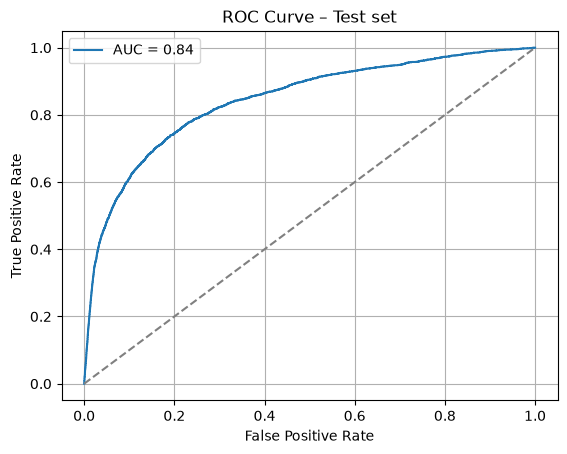

In [35]:
# ROC curve on the test set
fpr_t, tpr_t, _ = roc_curve(test['fraud'], test['p_hat'])
auc = roc_auc_score(test['fraud'], test['p_hat'])
plt.plot(fpr_t, tpr_t, label=f"AUC = {auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curve – Test set")
plt.legend(); plt.grid(True); plt.show()

### Choosing our cut-off
The ROC curve shows every possible trade-off between catching fraud and flagging good customers, but it doesn't
pick a cut-off. That's a business decision, so here is ours and why (numbers in the cut-off table above).

| Option | What happens | Our view |
|---|---|---|
| **Default 0.5** | Flags very few applications but misses most of the fraud | Too loose: most fraud gets the bonus |
| **Youden** | Catches the most fraud, but flags about one in five applications | Too strict: over 80% of the people it flags are good customers |
| **F1** | Balances precision and recall | Close in cost on this test set, but it isn't based on costs at all: it treats a missed fraud and a wrong review as equally bad, so it only lands near the cheapest point by luck |
| **Cost-based** | The cut-off with the lowest total dollar cost on the training set | **Our choice** |

**We choose the cost-based cut-off.** A missed fraud costs the bank several times more than reviewing a good
customer (see the cost cell above), so the line should sit lower than 0.5, but not so low that most of the people
we review are good customers. The cost-based
cut-off is the only option that weighs the two mistakes by what they actually cost. We then check two things a
manager would ask: (1) it still beats "no model" under the conservative costs (cell above), and (2) the review team
has room for the extra cases (next section).

In [36]:
# Classification table at the chosen (cost-based) cut-off
test["pred"] = (test["p_hat"] > cost_cut).astype(int)
pd.crosstab(test["fraud"], test["pred"], rownames=["Actual fraud"], colnames=["Predicted fraud"])

Predicted fraud,0,1
Actual fraud,,
0,47867,2543
1,1337,1251


In [37]:
# What each kind of mistake costs at the chosen cut-off (test set) - easy to check by hand
r = results.loc["Cost-based"]
tn = len(test) - r["fraud caught"] - r["good customers flagged"] - r["fraud missed"]
mistakes = pd.DataFrame({
    "count": [r["fraud caught"], r["fraud missed"], r["good customers flagged"], tn],
    "cost each": ["$0", f"varies (avg ${r['missed fraud cost'] / max(r['fraud missed'], 1):,.0f})", f"${COST_FP:,.2f}", "$0"],
    "total cost": [0, r["missed fraud cost"], r["false positive cost"], 0]},
    index=["Fraud caught (true positive)", "Missed fraud (false negative)", "Good customer reviewed (false positive)",
           "Good customer approved (true negative)"])
mistakes.loc["Total"] = [len(test), "", mistakes["total cost"].sum()]
mistakes.style.format({"count": "{:,.0f}", "total cost": "${:,.0f}"})

,count,cost each,total cost
Fraud caught (true positive),"1,251",$0,$0
Missed fraud (false negative),"1,337",varies (avg $381),"$509,936"
Good customer reviewed (false positive),"2,543",$80.24,"$204,044"
Good customer approved (true negative),"47,867",$0,$0
Total,"52,998",,"$713,979"


### Can the review team handle it? (`reviewer_team_staffing`, `daily_queue_metrics`, Aug 2026)
We score **every** August 2026 application (the busiest full month) and count how many the chosen cut-off would
send to review, then compare that with the fraud-review teams' spare capacity that month.

In [38]:
staffing, teams, queue = load("reviewer_team_staffing"), load("reviewer_teams"), load("daily_queue_metrics")
fraud_teams = teams.loc[teams["team_type"] == "fraud_review", "reviewer_team_id"]
capacity = staffing[staffing["staffing_date"].str.startswith("2026-08") & staffing["reviewer_team_id"].isin(fraud_teams)]["scheduled_capacity_cases"].sum()
current = queue[queue["queue_date"].str.startswith("2026-08") & queue["reviewer_team_id"].isin(fraud_teams)]["cases_arrived"].sum()
aug_all = pd.concat([train, test])
aug_all = aug_all[aug_all["month"] == "2026-08"]
aug_flags = int((aug_all["p_hat"] > cost_cut).sum())
print(f"Fraud-review capacity: {capacity:,} | already arriving: {current:,} | room: {capacity - current:,} cases")
print(f"Aug 2026 applications: {len(aug_all):,} | flagged at cut-off {cost_cut:.2f}: {aug_flags:,} -> "
      f"{'fits' if aug_flags <= capacity - current else 'does NOT fit'}")

Fraud-review capacity: 21,551 | already arriving: 3,310 | room: 18,241 cases
Aug 2026 applications: 37,544 | flagged at cut-off 0.12: 3,896 -> fits


### Lift and gains (Deck 7 function)

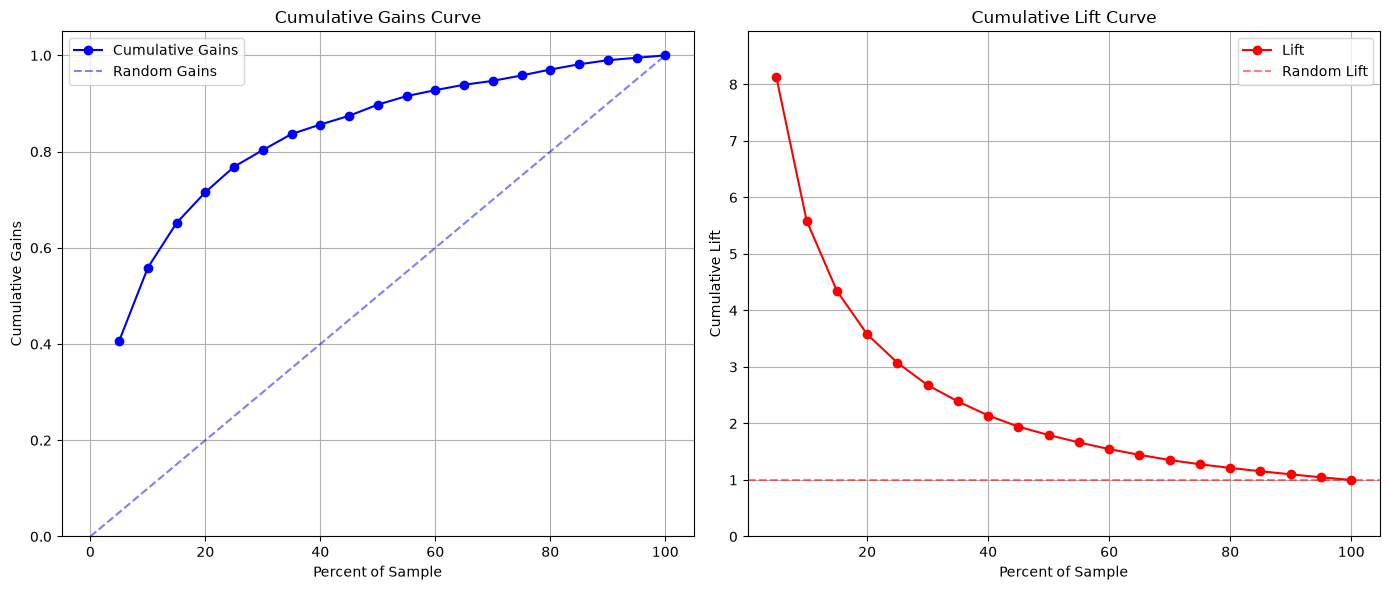

 top %  precision  lift  share of fraud captured
  0.01      0.480 9.833                    0.098
  0.05      0.397 8.125                    0.406
  0.10      0.273 5.588                    0.559
  0.20      0.175 3.578                    0.716


In [39]:
def plot_lift_and_gains(y_true, y_proba, n_bins=10):
    """Plot Lift and Cumulative Gains curves (function from the Deck 7 code)."""
    df = pd.DataFrame({'y_true': y_true, 'y_proba': y_proba})
    df = df.sort_values(by='y_proba', ascending=False).reset_index(drop=True)
    df['cum_total'] = np.arange(1, len(df) + 1)
    df['cum_positives'] = df['y_true'].cumsum()
    total_positives, total_samples = df['y_true'].sum(), len(df)
    df['cum_gains'] = df['cum_positives'] / total_positives
    df['cum_lift'] = df['cum_gains'] / (df['cum_total'] / total_samples)
    cutoffs = np.linspace(0, total_samples, n_bins + 1, dtype=int)
    cutoffs = cutoffs[cutoffs > 0]
    plot_points = df.loc[cutoffs - 1, ['cum_total', 'cum_gains', 'cum_lift']].copy()
    plot_points['percent_samples'] = plot_points['cum_total'] / total_samples * 100
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].plot(plot_points['percent_samples'], plot_points['cum_gains'], marker='o', color='blue', label='Cumulative Gains')
    axes[0].plot([0, 100], [0, 1], linestyle='--', color='blue', alpha=0.5, label='Random Gains')
    axes[0].set_xlabel('Percent of Sample'); axes[0].set_ylabel('Cumulative Gains'); axes[0].set_title('Cumulative Gains Curve')
    axes[0].set_ylim(0, 1.05); axes[0].grid(True); axes[0].legend()
    axes[1].plot(plot_points['percent_samples'], plot_points['cum_lift'], marker='o', color='red', label='Lift')
    axes[1].axhline(1, linestyle='--', color='red', alpha=0.5, label='Random Lift')
    axes[1].set_xlabel('Percent of Sample'); axes[1].set_ylabel('Cumulative Lift'); axes[1].set_title('Cumulative Lift Curve')
    axes[1].set_ylim(0, plot_points['cum_lift'].max() * 1.1); axes[1].grid(True); axes[1].legend()
    plt.tight_layout(); plt.show()

plot_lift_and_gains(test['fraud'], test['p_hat'], n_bins=20)

ranked = test.sort_values("p_hat", ascending=False).reset_index(drop=True)
lift_tbl = pd.DataFrame([{"top %": d, "precision": ranked["fraud"][: int(d * len(ranked))].mean(),
                          "lift": ranked["fraud"][: int(d * len(ranked))].mean() / ranked["fraud"].mean(),
                          "share of fraud captured": ranked["fraud"][: int(d * len(ranked))].sum() / ranked["fraud"].sum()}
                         for d in [0.01, 0.05, 0.10, 0.20]])
print(lift_tbl.round(3).to_string(index=False))

### Which fraud types are caught? (cost-based cut-off)

In [40]:
types = inv_status[inv_status["status"] == "confirmed"].drop_duplicates("application_id")[["application_id", "fraud_type"]]
test[test["fraud"] == 1].merge(types, on="application_id", how="left").groupby("fraud_type")["pred"].agg(
    fraud_cases="size", recall="mean").style.format({"recall": "{:.1%}"})

,fraud_cases,recall
fraud_type,,
bonus_abuse,748,67.8%
first_party,374,22.2%
stolen_identity,840,42.0%
synthetic_identity,626,49.2%


### Benchmark: the bank's current fraud score
`decisions_reviews` stores the score the bank's existing model (`legacy_fraud_scorer`) gave each application at its
automatic decision. It's used **only for comparison** on the same test applications, never as a model input.

In [41]:
legacy = load("decisions_reviews")[["application_id", "event_type", "fraud_score_at_event"]]
legacy = legacy[legacy["event_type"] == "auto_decision"].drop_duplicates("application_id")
bench = test.merge(legacy, on="application_id", how="inner")
legacy_auc = roc_auc_score(bench["fraud"], bench["fraud_score_at_event"])
team_auc = roc_auc_score(bench["fraud"], bench["p_hat"])
lr = bench.sort_values("fraud_score_at_event", ascending=False)["fraud"]
tr5 = bench.sort_values("p_hat", ascending=False)["fraud"]
k = int(0.05 * len(bench))
print(f"Applications compared: {len(bench):,}")
print(f"Current bank score AUC: {legacy_auc:.3f} | Team model AUC: {team_auc:.3f}")
print(f"Fraud found in the riskiest 5%: current score {lr[:k].sum() / lr.sum():.1%} | team model {tr5[:k].sum() / tr5.sum():.1%}")

Applications compared: 52,998
Current bank score AUC: 0.651 | Team model AUC: 0.844
Fraud found in the riskiest 5%: current score 6.4% | team model 40.6%


## 11. Final model vs. a first-pass model
The first-pass model uses only the initial feature set (Section 3), refit here on the same train/test split and costs.
This shows how much the additional team features add.

In [42]:
first_pass_final = ["device_linked_to_past_fraud", "seconds_per_page_was_missing", "referral_code_burst",
              "device_age_days", "shared_device_applicants_90d", "prior_apps_same_applicant",
              "first_touch_to_submit_min", "seconds_per_page"]
Xa, Xa_test = prep(initial_features)
ra = sm.Logit(y, sm.add_constant(Xa[first_pass_final])).fit(disp=0)
cost_cols = ["fraud", "cost_if_missed", "cost_if_missed_low"]
fp_eval = test[cost_cols].assign(p_hat=ra.predict(sm.add_constant(Xa_test[first_pass_final], has_constant="add")))
fp_train = train[cost_cols].assign(p_hat=ra.predict(sm.add_constant(Xa[first_pass_final])))
fp_cut = min([classify(fp_train, c) for c in np.arange(0.01, 0.60, 0.01)], key=lambda r: r["total cost"])["cut-off"]

rows = []
for name, tr, te, cut, r in [("First-pass model", fp_train, fp_eval, fp_cut, ra), ("Final team model", train, test, cost_cut, result)]:
    b = classify(te, cut)
    rows.append({"model": name, "variables": len(r.params) - 1, "train AUC": roc_auc_score(tr["fraud"], tr["p_hat"]),
                 "test AUC": roc_auc_score(te["fraud"], te["p_hat"]), "pseudo R²": r.prsquared, "cut-off": cut,
                 "fraud caught": b["sensitivity/recall"], "precision": b["precision"], "flagged %": b["flagged %"],
                 "test cost": b["total cost"]})
pd.DataFrame(rows).set_index("model").style.format({"train AUC": "{:.3f}", "test AUC": "{:.3f}", "pseudo R²": "{:.3f}",
    "cut-off": "{:.2f}", "fraud caught": "{:.1%}", "precision": "{:.1%}", "flagged %": "{:.1%}", "test cost": "${:,.0f}"})

,variables,train AUC,test AUC,pseudo R²,cut-off,fraud caught,precision,flagged %,test cost
model,,,,,,,,,
First-pass model,8,0.783,0.775,0.175,0.13,37.1%,35.8%,5.1%,"$751,949"
Final team model,20,0.849,0.844,0.229,0.12,48.3%,33.0%,7.2%,"$713,979"
